# Week 4 Day 3 ? Regression Analysis

## Objective
Explore relationships between variables using Pearson and Spearman correlation, visualize correlations, build a simple linear regression model, and evaluate its performance.

**Business context:** Regression can help businesses understand relationships between variables and estimate outcomes.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries imported successfully")


Libraries imported successfully


## 1. Load and Explore the Dataset

We will use the internship sales dataset. We will inspect its columns and identify numerical variables for correlation analysis.


In [2]:
from pathlib import Path

data_path = Path("../../week-01/day-05/sales_data.csv")
df = pd.read_csv(data_path)

display(df.head())
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
display(df.isnull().sum())


,sale_id,customer_name,product,category,region,amount,sale_date,discount
0,1,Ananya,Laptop,Electronics,South,55000,01-09-2026,0.10
1,2,Rahul,Phone,Electronics,North,25000,02-09-2026,0.05
2,3,Priya,Chair,Furniture,West,4500,03-09-2026,NaN
3,4,Arjun,Desk,Furniture,South,8000,04-09-2026,0.00
4,5,Meera,Headphones,Electronics,East,2000,05-09-2026,0.15


Dataset shape: (10, 8)

Columns: ['sale_id', 'customer_name', 'product', 'category', 'region', 'amount', 'sale_date', 'discount']

Missing values:


sale_id          0
customer_name    0
product          0
category         0
region           0
amount           0
sale_date        0
discount         3
dtype: int64

## 2. Pearson and Spearman Correlation

- **Pearson correlation** measures the strength of a linear relationship.
- **Spearman correlation** measures the strength of a monotonic relationship using ranks.
- Correlation ranges from -1 to +1. Correlation does not prove causation.


In [3]:
numeric_df = df.select_dtypes(include="number").copy()

# Remove identifier columns from correlation analysis
numeric_df = numeric_df.drop(columns=["sale_id"], errors="ignore")

print("Pearson correlation:")
display(numeric_df.corr(method="pearson"))

print("Spearman correlation:")
display(numeric_df.corr(method="spearman"))


Pearson correlation:


,amount,discount
amount,1.000000,0.285316
discount,0.285316,1.000000


Spearman correlation:


,amount,discount
amount,1.000000,0.290957
discount,0.290957,1.000000


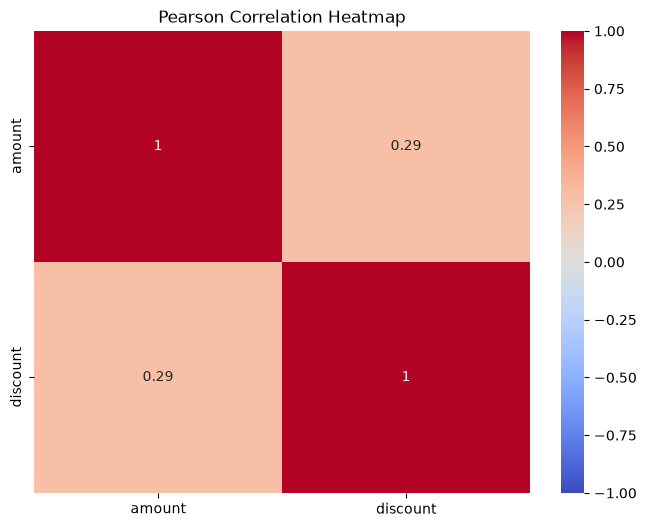

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(method="pearson"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation Heatmap")
plt.show()


## 3. Scatter Matrix

A scatter matrix helps visualize pairwise relationships among numerical variables. Diagonal plots show each variable's distribution.


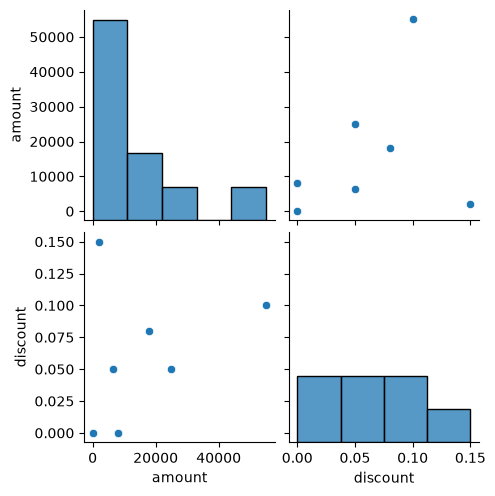

In [5]:
if len(numeric_df.columns) >= 2:
    sns.pairplot(numeric_df)
    plt.show()
else:
    print("Not enough numerical columns for a scatter matrix.")


## 4. Simple Linear Regression

We will use discount to predict sales amount. Rows with missing values in either variable are excluded.

**Note:** This dataset is small, so the model is for learning regression concepts and should not be treated as a reliable business forecasting model.


In [6]:
model_df = df[["discount", "amount"]].dropna().copy()

X = model_df[["discount"]]
y = model_df["amount"]

print("Rows used for regression:", len(model_df))
display(model_df.head())

if len(model_df) < 4:
    raise ValueError("Not enough complete rows for a train/test regression example.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercept:", round(model.intercept_, 2))
print("Coefficient:", round(model.coef_[0], 2))


Rows used for regression: 7


,discount,amount
0,0.10,55000
1,0.05,25000
3,0.00,8000
4,0.15,2000
6,0.00,150


Intercept: 4854.17
Coefficient: -13833.33


## 5. Evaluate the Model

- **R?:** Indicates how much variation in the target is explained by the model.
- **MAE:** Average absolute prediction error.
- **RMSE:** Gives larger errors more weight than MAE.


In [7]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R?: {r2:.3f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")


R?: -3.261
MAE: 28873.06
RMSE: 33128.99


## 6. Plot Regression Line

The plot compares actual sales amounts with the fitted regression line.


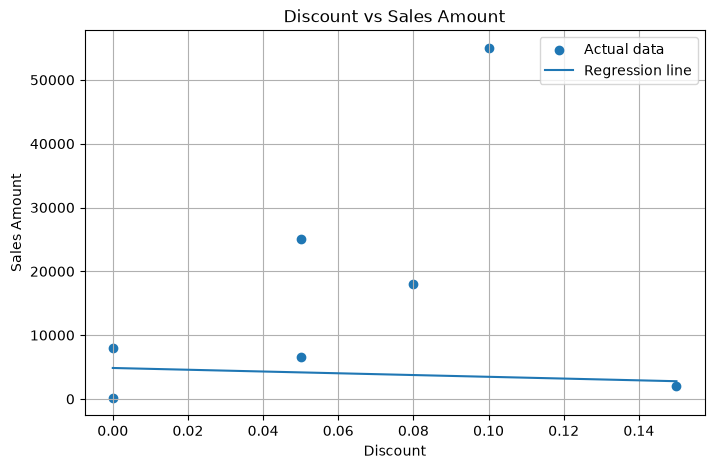

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual data")

line_x = np.linspace(X["discount"].min(), X["discount"].max(), 100)
line_y = model.predict(pd.DataFrame({"discount": line_x}))

plt.plot(line_x, line_y, label="Regression line")
plt.title("Discount vs Sales Amount")
plt.xlabel("Discount")
plt.ylabel("Sales Amount")
plt.legend()
plt.grid(True)
plt.show()


## 7. Residual Analysis

A residual is the difference between an actual value and its predicted value. Residual plots help identify patterns that may indicate a poor model fit.


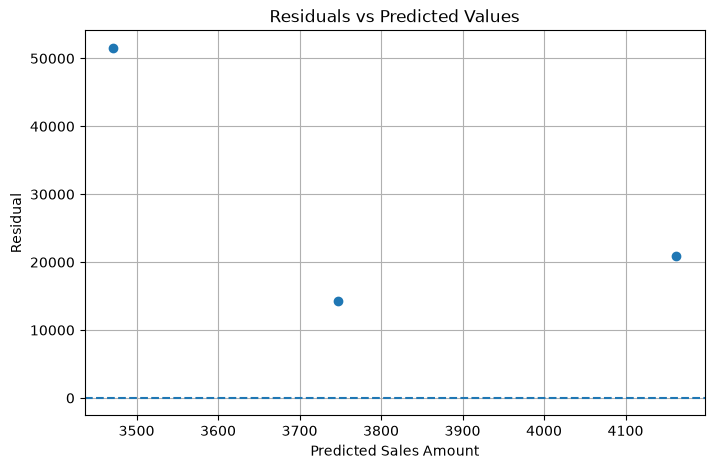

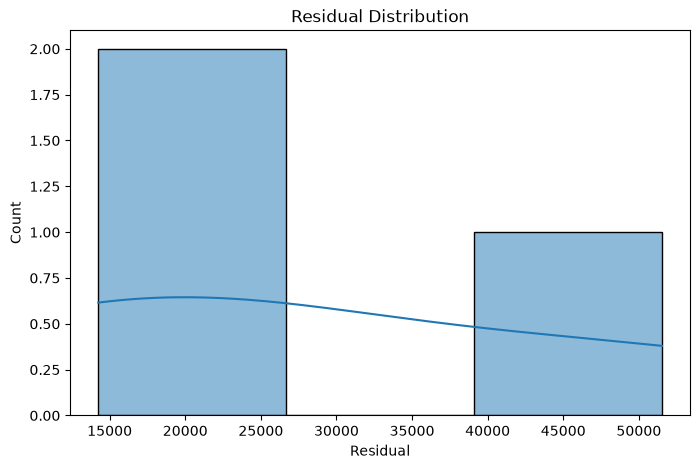

Residual mean: 28873.06


In [9]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Sales Amount")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.show()

print("Residual mean:", round(residuals.mean(), 2))


## Conclusion

- Pearson correlation measures linear relationships.
- Spearman correlation measures rank-based monotonic relationships.
- Linear regression estimates a target using one or more input variables.
- R?, MAE, and RMSE help evaluate model performance.
- Residual plots help check whether errors show patterns.

### Viva Notes

1. **Correlation vs causation:** Correlation shows association; causation means one variable directly affects another.
2. **R?:** Measures the proportion of target variation explained by the model.
3. **Pearson vs Spearman:** Pearson uses actual values for linear relationships; Spearman uses ranks for monotonic relationships.
